In [283]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

In [284]:
df=pd.read_csv('customer_churn.csv')
df

,Names,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Onboard_date,Location,Company,Churn
0,Cameron Williams,42.0,11066.80,0,7.22,8.0,2013-08-30 07:00:40,"10265 Elizabeth Mission Barkerburgh, AK 89518",Harvey LLC,1
1,Kevin Mueller,41.0,11916.22,0,6.50,11.0,2013-08-13 00:38:46,"6157 Frank Gardens Suite 019 Carloshaven, RI 1...",Wilson PLC,1
2,Eric Lozano,38.0,12884.75,0,6.67,12.0,2016-06-29 06:20:07,"1331 Keith Court Alyssahaven, DE 90114","Miller, Johnson and Wallace",1
3,Phillip White,42.0,8010.76,0,6.71,10.0,2014-04-22 12:43:12,"13120 Daniel Mount Angelabury, WY 30645-4695",Smith Inc,1
4,Cynthia Norton,37.0,9191.58,0,5.56,9.0,2016-01-19 15:31:15,"765 Tricia Row Karenshire, MH 71730",Love-Jones,1
...,...,...,...,...,...,...,...,...,...,...
895,Paul Miller,42.0,12800.82,1,3.62,8.0,2007-12-01 13:29:34,"9316 Julian Fort Suite 328 North Leslie, ME 43961",Evans-Lucero,0
896,Natalie Hodges,52.0,9893.92,0,6.91,7.0,2008-12-28 15:23:58,"8419 William Square Apt. 695 Martinville, RI 3...",Perry and Sons,0
897,Ana Smith,45.0,12056.18,0,5.46,4.0,2014-06-20 05:10:09,Unit 8633 Box 8738 DPO AA 14126-5026,Schneider-Smith,0
898,Justin Leonard,51.0,6517.93,1,5.47,10.0,2012-05-30 00:15:43,"49800 Torres Ways Suite 886 West Bradleybury, ...",Robles-Abbott,0


In [285]:
df.duplicated().sum()

np.int64(0)

In [286]:
df["Churn"].value_counts()

Churn
0    750
1    150
Name: count, dtype: int64

In [287]:
df['Churn'].value_counts(normalize=True)*100

Churn
0    83.333333
1    16.666667
Name: proportion, dtype: float64

In [288]:
df.groupby('Churn')['Age'].mean()

Churn
0    41.581333
1    42.993333
Name: Age, dtype: float64

In [289]:
df.groupby('Churn')['Total_Purchase'].mean()

Churn
0    10036.952853
1    10192.179933
Name: Total_Purchase, dtype: float64

In [290]:
df.groupby('Churn')['Years'].mean()

Churn
0    5.151067
1    5.883600
Name: Years, dtype: float64

In [291]:
df.groupby('Churn')['Num_Sites'].mean()

Churn
0     8.173333
1    10.660000
Name: Num_Sites, dtype: float64

In [292]:
df['Location'].unique()

<StringArray>
[               '10265 Elizabeth Mission Barkerburgh, AK 89518',
           '6157 Frank Gardens Suite 019 Carloshaven, RI 17756',
                       '1331 Keith Court Alyssahaven, DE 90114',
                 '13120 Daniel Mount Angelabury, WY 30645-4695',
                          '765 Tricia Row Karenshire, MH 71730',
           '6187 Olson Mountains East Vincentborough, PR 74359',
                '4846 Savannah Road West Justin, IA 87713-3460',
      '25271 Roy Expressway Suite 147 Brownport, FM 59852-6150',
        '3725 Caroline Stravenue South Christineview, MA 82059',
          '363 Sandra Lodge Suite 144 South Ann, WI 51655-7561',
 ...
             '6239 Timothy Overpass Carmenhaven, FM 05708-0772',
          '339 Jeffrey River Suite 638 Fergusonville, DC 25987',
 '276 Thompson Field Apt. 992 South Victoriaton, SC 12848-8182',
              '393 Stephens Field South Michelleside, MI 26930',
                   '00154 Ashley Course Shannonville, UT 52907',
      

In [293]:
df['Company'].unique()

<StringArray>
[                  'Harvey LLC',                   'Wilson PLC',
  'Miller, Johnson and Wallace',                    'Smith Inc',
                   'Love-Jones',                 'Kelly-Warren',
            'Reynolds-Sheppard',                   'Singh-Cole',
                    'Lopez PLC',                'Reed-Martinez',
 ...
 'Mosley, Tate and Blankenship',    'Jordan, Beasley and Moore',
              'Santiago-Waller',      'Little, White and Davis',
                  'Ewing Group',                 'Gomez-Clarke',
                'Chavez-Howard',                 'Evans-Lucero',
              'Schneider-Smith',                'Robles-Abbott']
Length: 873, dtype: str

In [294]:
df['Names'].unique()

<StringArray>
['Cameron Williams',    'Kevin Mueller',      'Eric Lozano',
    'Phillip White',   'Cynthia Norton', 'Jessica Williams',
      'Eric Butler',    'Zachary Walsh',      'Ashlee Carr',
   'Jennifer Lynch',
 ...
       'Jason West',       'Adam Moore',    'Brandon Ortiz',
   'Cindy Marshall',   'Matthew Barnes',      'Paul Miller',
   'Natalie Hodges',        'Ana Smith',   'Justin Leonard',
  'Joseph Williams']
Length: 899, dtype: str

In [295]:
pd.crosstab(
    df['Account_Manager'],
    df['Churn'],
    normalize='index'
)*100

Churn,0,1
Account_Manager,,
0,85.867238,14.132762
1,80.600462,19.399538


In [296]:
pd.crosstab(
    df['Location'],
    df['Churn'],
    normalize='index'
)*100

Churn,0,1
Location,,
"00103 Jeffrey Crest Apt. 205 Padillaville, IA 90755",100.0,0.0
"00154 Ashley Course Shannonville, UT 52907",100.0,0.0
"002 Gutierrez Mountains Hayesburgh, GU 73502-4691",100.0,0.0
"007 Davis Squares Flynnchester, SC 79849",100.0,0.0
"007 Shaw Trafficway Patrickstad, PA 29094-0827",100.0,0.0
...,...,...
Unit 8633 Box 8738 DPO AA 14126-5026,100.0,0.0
Unit 8716 Box 6865 DPO AE 33780,100.0,0.0
Unit 9127 Box 5819 DPO AE 24161,100.0,0.0


In [297]:
df.drop(
    ['Names','Location','Company'],
    axis=1,
    inplace=True
)

In [298]:
df.columns

Index(['Age', 'Total_Purchase', 'Account_Manager', 'Years', 'Num_Sites',
       'Onboard_date', 'Churn'],
      dtype='str')

In [299]:
df['Onboard_date']=pd.to_datetime(df['Onboard_date'])

In [300]:
df['Onboard_Year']=df['Onboard_date'].dt.year

In [301]:
df['Onboard_Month']=df['Onboard_date'].dt.month

In [302]:
df[['Onboard_date','Onboard_Year','Onboard_Month']].head()

,Onboard_date,Onboard_Year,Onboard_Month
0,2013-08-30 07:00:40,2013,8
1,2013-08-13 00:38:46,2013,8
2,2016-06-29 06:20:07,2016,6
3,2014-04-22 12:43:12,2014,4
4,2016-01-19 15:31:15,2016,1


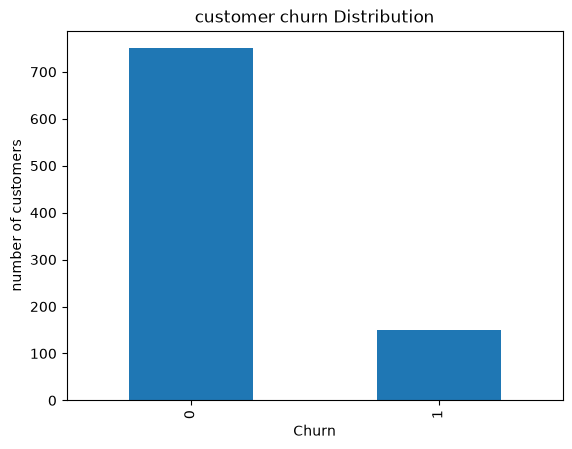

In [303]:
df['Churn'].value_counts().plot(kind='bar')
plt.xlabel('Churn')
plt.ylabel('number of customers')
plt.title("customer churn Distribution")
plt.show()

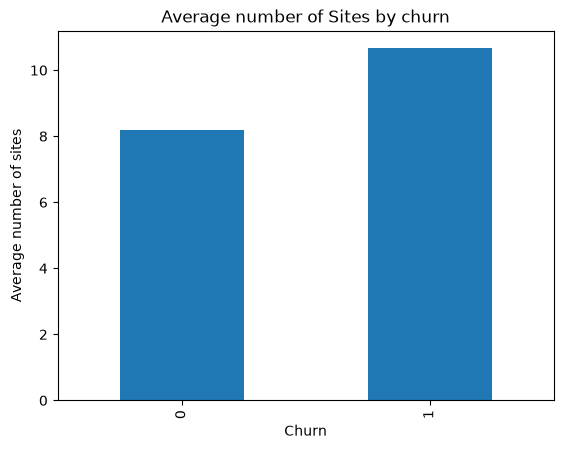

In [304]:
df.groupby('Churn')['Num_Sites'].mean().plot(kind='bar')
plt.xlabel('Churn')
plt.ylabel('Average number of sites')
plt.title('Average number of Sites by churn')
plt.show()

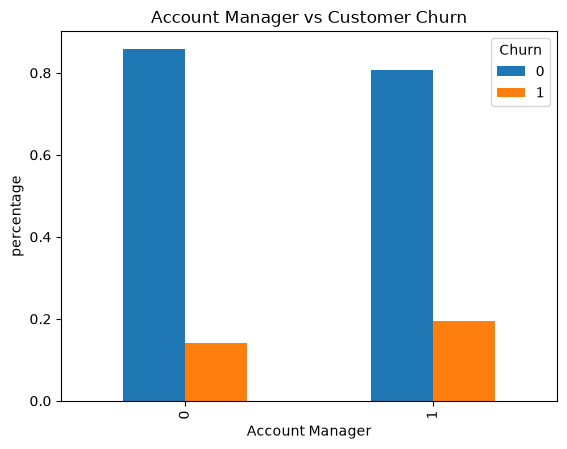

In [305]:
pd.crosstab(
    df['Account_Manager'],
    df['Churn'],
    normalize="index"
).plot(kind='bar')
plt.xlabel("Account Manager")
plt.ylabel("percentage")
plt.title("Account Manager vs Customer Churn")
plt.legend(title='Churn')
plt.show()

In [306]:
df.to_csv('customer_churn.cleaned.csv',index=False)

In [307]:
print(df.head())

    Age  Total_Purchase  Account_Manager  Years  Num_Sites  \
0  42.0        11066.80                0   7.22        8.0   
1  41.0        11916.22                0   6.50       11.0   
2  38.0        12884.75                0   6.67       12.0   
3  42.0         8010.76                0   6.71       10.0   
4  37.0         9191.58                0   5.56        9.0   

         Onboard_date  Churn  Onboard_Year  Onboard_Month  
0 2013-08-30 07:00:40      1          2013              8  
1 2013-08-13 00:38:46      1          2013              8  
2 2016-06-29 06:20:07      1          2016              6  
3 2014-04-22 12:43:12      1          2014              4  
4 2016-01-19 15:31:15      1          2016              1  


In [308]:
print(df.shape)

(900, 9)


In [309]:
df.columns

Index(['Age', 'Total_Purchase', 'Account_Manager', 'Years', 'Num_Sites',
       'Onboard_date', 'Churn', 'Onboard_Year', 'Onboard_Month'],
      dtype='str')

In [310]:
x=df.drop(["Churn","Onboard_date"], axis=1)
y=df["Churn"]

In [311]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [312]:
model=DecisionTreeClassifier(criterion='entropy',max_depth=5)
model.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [313]:
y_predict=model.predict(x_test)

In [314]:
accuracy_score(y_test,y_predict)

0.8777777777777778

In [315]:
x_predict=model.predict(x_train)

In [317]:
accuracy_score(y_train,x_predict)

0.9194444444444444

In [320]:
cm = confusion_matrix(y_test,y_predict)
print(cm)


[[137  11]
 [ 11  21]]


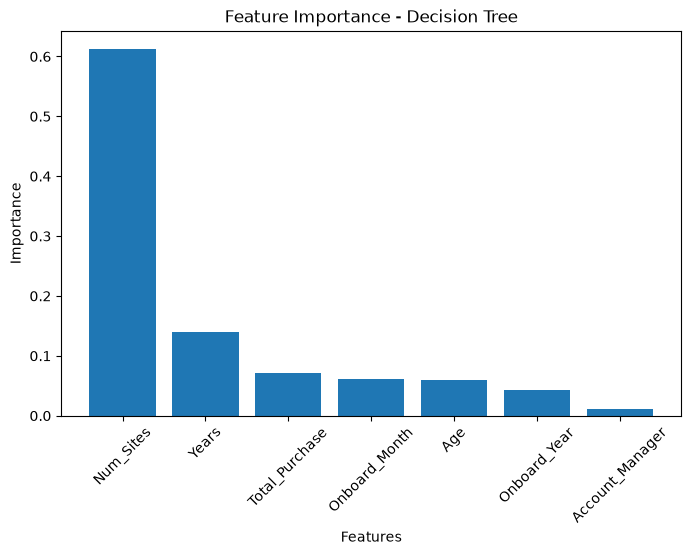

In [323]:
plt.figure(figsize=(8,5))

plt.bar(importance["Feature"], importance["Importance"])

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance - Decision Tree")

plt.xticks(rotation=45)
plt.show()